<a href="https://colab.research.google.com/github/12tangent/Supervised_Learning_Tanay_Choudhari_2026_710/blob/main/Supervised_Learning_Part4_Python_Data_Visualisation_Practical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Python Data Visualisation

**Topic:** How visualisation reveals skewness, unusual values, spread and relationships  


## 1. What is data visualisation?

Data visualisation is the graphical representation of information. It converts rows and columns of values into charts that help us see patterns.

Imagine receiving a spreadsheet containing 5,000 employee salaries. Reading every salary one by one is difficult. A histogram can quickly show where salaries are concentrated and whether a small number of very high salaries are present.

### What can visualisation reveal?

| Feature | Meaning | Useful chart |
|---|---|---|
| Skewness | Whether a distribution has a longer tail on one side | Histogram |
| Unusual values | Observations far from most of the data | Boxplot |
| Spread | How widely values are dispersed | Boxplot, histogram |
| Relationships | How two numerical variables move together | Scatter plot, heatmap |

A chart should always be followed by interpretation. Ask: *What do I see? What might it mean? What else should I check?*

## 2. Set up the Python environment

We use:
- **Pandas:** data tables and descriptive statistics.
- **NumPy:** numerical calculations and simulated data.
- **Matplotlib:** general plotting.
- **Seaborn:** statistical charts with convenient defaults.
- **Statistics:** sample standard deviation.

If the packages are missing, run the installation command in a notebook cell.

In [1]:
# If required, install packages:
# %pip install pandas numpy matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statistics

sns.set_theme(style="whitegrid")
print("Setup complete.")

Setup complete.


# Part A — Skewness

## 3. Understanding skewness

**Skewness describes the asymmetry of a distribution.** It tells us whether the data is balanced around its centre or has a longer tail on one side.

### Three common shapes

1. **Approximately symmetric:** Both sides of the distribution have a broadly similar shape.
2. **Positive skew (right skew):** The longer tail stretches towards larger values. Most observations are often concentrated towards the lower end.
3. **Negative skew (left skew):** The longer tail stretches towards smaller values. Most observations are often concentrated towards the higher end.

**Memory tip:** The direction of skewness is named after the direction of the long tail.

### Why is this useful?

Salary, house-price and transaction-value data can be positively skewed. A small number of very large values may pull the mean upwards. In such cases, the median can be a more representative measure of a typical observation than the mean.

## 4. Visualise three distribution shapes

The following examples use simulated values. The purpose is to understand the shapes, not to represent a real population.

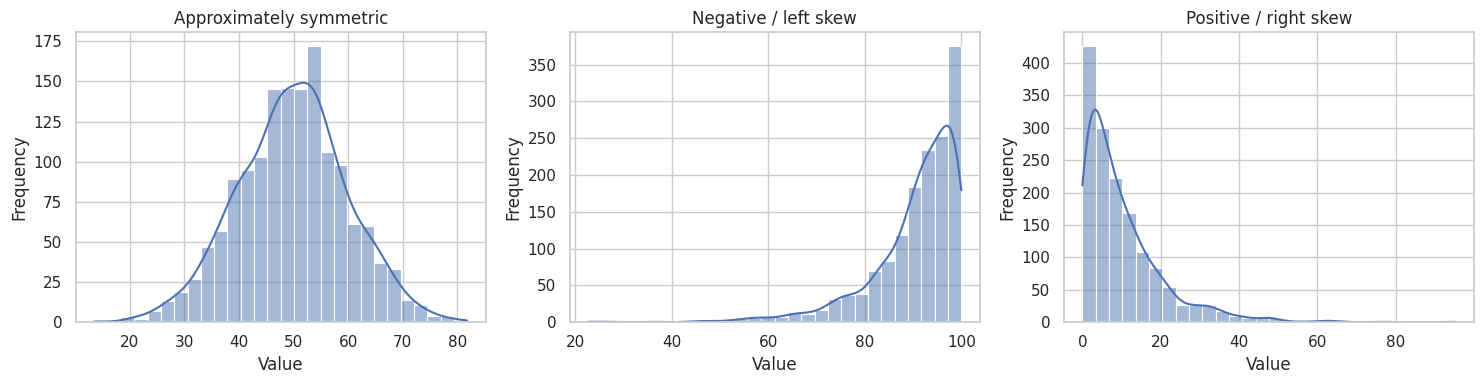

In [2]:
rng = np.random.default_rng(42)

symmetric = rng.normal(loc=50, scale=10, size=1500)
positive_skew = rng.exponential(scale=10, size=1500)
negative_skew = 100 - rng.exponential(scale=10, size=1500)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(symmetric, bins=28, kde=True, ax=axes[0])
axes[0].set_title("Approximately symmetric")

sns.histplot(negative_skew, bins=28, kde=True, ax=axes[1])
axes[1].set_title("Negative / left skew")

sns.histplot(positive_skew, bins=28, kde=True, ax=axes[2])
axes[2].set_title("Positive / right skew")

for ax in axes:
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### How to read these histograms

- Look at the location of the tallest bars: where are most observations?
- Look at the tail: in which direction does the distribution extend?
- Compare the left and right sides around the centre.

A histogram's appearance can change with the number of bins. Try changing `bins=28` to `bins=10` or `bins=40`. The overall pattern should be interpreted carefully rather than relying on one bin setting.

## 5. Worked example: employee salaries

Suppose the monthly salaries (in rupees) of ten employees are:

₹20,000, ₹22,000, ₹23,000, ₹25,000, ₹27,000, ₹28,000, ₹30,000, ₹32,000, ₹35,000 and ₹1,50,000.

Nine values are between ₹20,000 and ₹35,000. One value is much higher. Let's see how this affects the distribution.

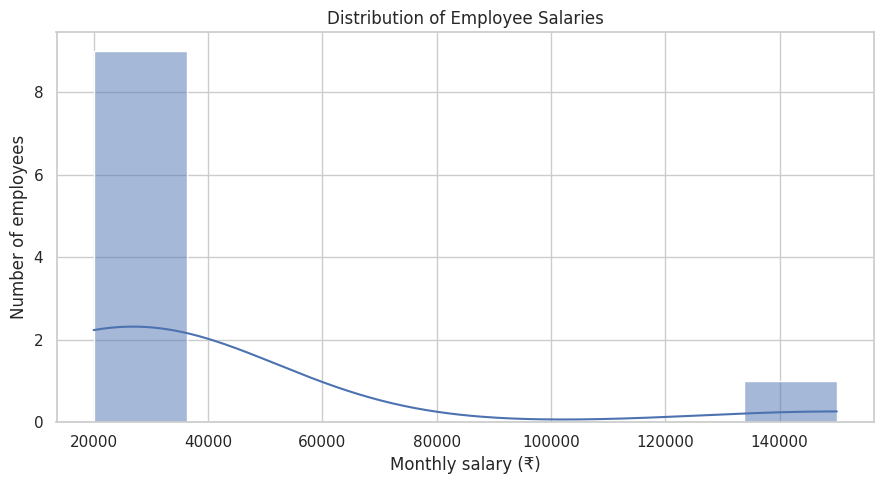

In [3]:
salary = [20000, 22000, 23000, 25000, 27000,
          28000, 30000, 32000, 35000, 150000]

plt.figure(figsize=(9, 5))
sns.histplot(salary, bins=8, kde=True)
plt.title("Distribution of Employee Salaries")
plt.xlabel("Monthly salary (₹)")
plt.ylabel("Number of employees")
plt.tight_layout()
plt.show()

### Interpretation

The salary of ₹1,50,000 stretches the distribution towards the right. The distribution is therefore positively skewed.

Let's compare the mean, median and skewness value.

In [4]:
salary_series = pd.Series(salary)

print("Mean salary:   ₹", round(salary_series.mean(), 2))
print("Median salary: ₹", round(salary_series.median(), 2))
print("Skewness:      ", round(salary_series.skew(), 3))

Mean salary:   ₹ 39200.0
Median salary: ₹ 27500.0
Skewness:       3.08


### What do the numbers tell us?

- The **mean** is sensitive to very high or very low values.
- The **median** is the middle observation after sorting the values.
- A positive skewness statistic indicates right-skewness.

Pandas `Series.skew()` calculates a sample skewness statistic. A value above zero indicates positive skew, below zero indicates negative skew, and a value near zero suggests approximate symmetry. There is no single universal cut-off that classifies every dataset.

**Business interpretation:** If a company reports only the average salary, the high salary may make the typical employee's salary appear higher than it is. Reporting the median alongside the mean can provide a fuller picture.

# Part B — Unusual Values and Outliers

## 6. What is an outlier?

An **outlier** is an observation that is unusually far from the rest of the data.

Possible reasons include:
- A data-entry mistake.
- A measurement or instrument error.
- Incorrect units.
- A rare but genuine event.
- Natural variation.

An outlier is not automatically incorrect. Investigate it before deciding whether to correct, retain or exclude it.

## 7. Worked example: student marks

Consider these marks:

`65, 70, 72, 68, 75, 78, 71, 69, 73, 150`

The value 150 is far above the remaining marks. If the examination is out of 100, it is impossible and likely indicates a data-quality issue. If the examination has a different scale, we need to check the context.

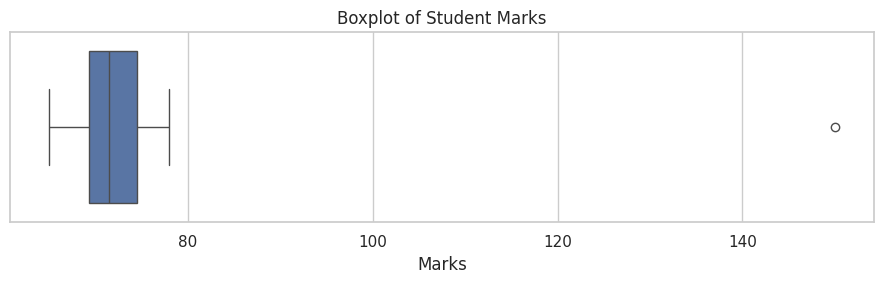

In [5]:
marks = [65, 70, 72, 68, 75, 78, 71, 69, 73, 150]

plt.figure(figsize=(9, 3))
sns.boxplot(x=marks)
plt.title("Boxplot of Student Marks")
plt.xlabel("Marks")
plt.tight_layout()
plt.show()

### Understand the boxplot

- **Median:** The line inside the box.
- **Q1:** The 25th percentile.
- **Q3:** The 75th percentile.
- **IQR:** Q3 minus Q1; the box covers the middle 50% of values.
- **Whiskers:** Extend to the most extreme observations that are not flagged as outliers under the boxplot rule.
- **Separate points:** Potential outliers under that rule.

A boxplot is a screening tool. It does not tell us why a value is unusual.

## 8. Detect potential outliers using the IQR method

The Interquartile Range (IQR) measures the spread of the middle 50% of observations.

\[
IQR = Q3 - Q1
\]

The commonly used fences are:

\[
Lower\ Fence = Q1 - 1.5 \times IQR
\]

\[
Upper\ Fence = Q3 + 1.5 \times IQR
\]

Any value below the lower fence or above the upper fence is flagged as a potential outlier.

In [6]:
marks_series = pd.Series(marks)

Q1 = marks_series.quantile(0.25)
Q3 = marks_series.quantile(0.75)
IQR = Q3 - Q1

lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

potential_outliers = marks_series[
    (marks_series < lower_fence) |
    (marks_series > upper_fence)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower fence:", lower_fence)
print("Upper fence:", upper_fence)
print("Potential outliers:", potential_outliers.tolist())

Q1: 69.25
Q3: 74.5
IQR: 5.25
Lower fence: 61.375
Upper fence: 82.375
Potential outliers: [150]


### Step-by-step interpretation

1. Find the 25th percentile (Q1).
2. Find the 75th percentile (Q3).
3. Calculate IQR = Q3 − Q1.
4. Calculate the lower and upper fences.
5. Identify values outside the fences.

**Important:** Quartile calculations can differ slightly across software because quantile interpolation conventions may vary. The IQR rule is a common screening method, not a universal test of data validity. For highly skewed data, use domain knowledge and consider additional methods.

# Part C — Spread and Variability

## 9. What is spread?

Spread tells us how widely observations are distributed.

Consider two groups:

- **Group A:** 48, 49, 50, 51, 52
- **Group B:** 20, 35, 50, 65, 80

Both groups have the same mean (50), but their observations are distributed very differently.

### Common measures of spread

| Measure | Meaning |
|---|---|
| Range | Maximum − minimum |
| Variance | Average squared deviation from the mean, with a sample degrees-of-freedom adjustment when calculated as sample variance |
| Standard deviation | Square root of variance; expressed in the original units |
| IQR | Q3 − Q1; spread of the middle 50% |

Range and standard deviation are sensitive to extreme values. IQR is generally more resistant to them.

In [7]:
group_A = [48, 49, 50, 51, 52]
group_B = [20, 35, 50, 65, 80]

def spread_summary(values):
    series = pd.Series(values)
    return {
        "Mean": series.mean(),
        "Minimum": series.min(),
        "Maximum": series.max(),
        "Range": series.max() - series.min(),
        "Sample standard deviation": series.std(),
        "IQR": series.quantile(0.75) - series.quantile(0.25)
    }

spread_comparison = pd.DataFrame({
    "Group A": spread_summary(group_A),
    "Group B": spread_summary(group_B)
})

display(spread_comparison)

,Group A,Group B
Mean,50.000000,50.000000
Minimum,48.000000,20.000000
Maximum,52.000000,80.000000
Range,4.000000,60.000000
Sample standard deviation,1.581139,23.717082
IQR,2.000000,30.000000


### Visual comparison of spread

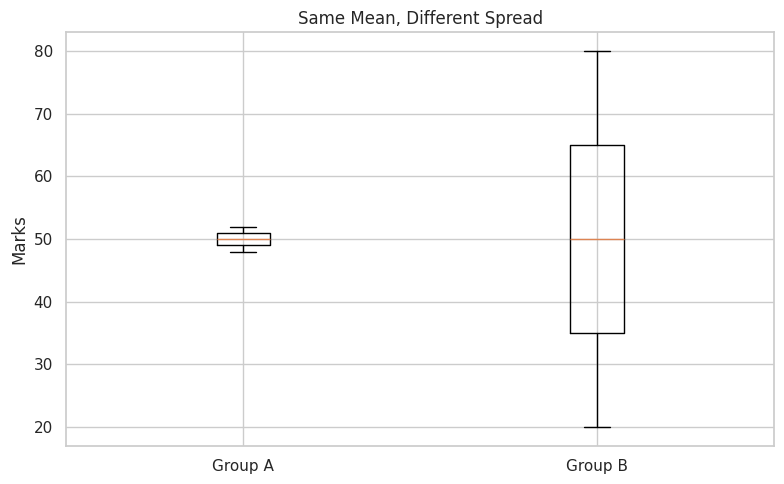

In [8]:
plt.figure(figsize=(8, 5))
plt.boxplot([group_A, group_B], tick_labels=["Group A", "Group B"])
plt.title("Same Mean, Different Spread")
plt.ylabel("Marks")
plt.tight_layout()
plt.show()

### Interpretation

- Both groups have a mean of 50.
- Group A has a range of 4. Its values are tightly clustered.
- Group B has a range of 60. Its values are widely spread.
- Group B has a larger standard deviation.

**Key learning:** Two datasets can have the same average but very different variability. Always examine spread along with the mean.

# Part D — Relationships Between Variables

## 10. What is a relationship?

A relationship describes how two variables vary together. A scatter plot places one variable on the horizontal axis (X) and another on the vertical axis (Y). Each dot represents one observation containing a pair of values.

Three common patterns:

- **Positive association:** As X increases, Y tends to increase.
- **Negative association:** As X increases, Y tends to decrease.
- **No clear linear pattern:** There is no obvious straight-line trend.

A scatter plot can also reveal clusters, curved patterns and unusual observations.

## 11. Visualise positive, negative and no clear linear pattern

The following simulated examples help distinguish the three patterns.

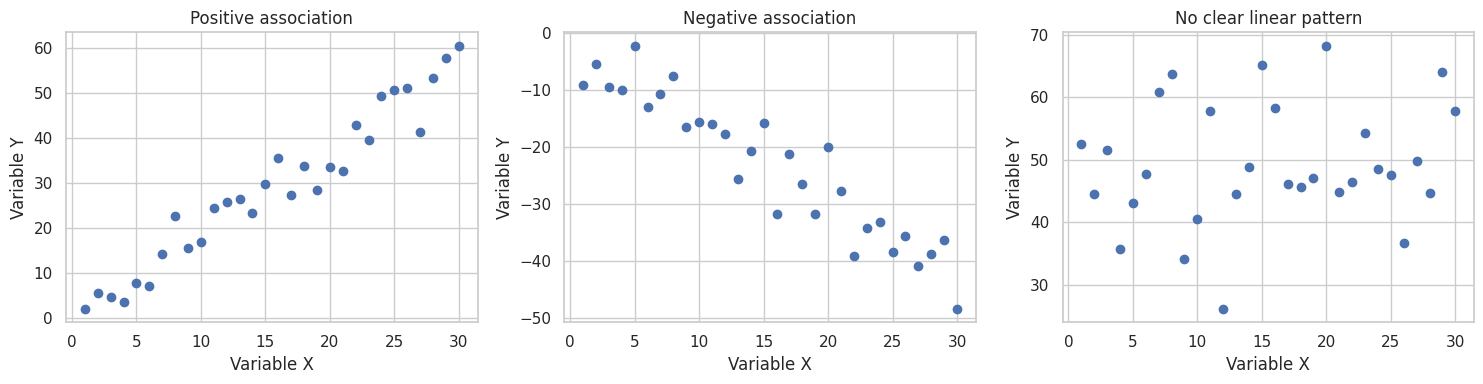

In [9]:
rng = np.random.default_rng(7)
x = np.arange(1, 31)

y_positive = 2 * x + rng.normal(0, 5, len(x))
y_negative = -1.5 * x + rng.normal(0, 5, len(x))
y_no_linear = rng.normal(50, 12, len(x))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, y, title in zip(
    axes,
    [y_positive, y_negative, y_no_linear],
    ["Positive association", "Negative association", "No clear linear pattern"]
):
    ax.scatter(x, y)
    ax.set_title(title)
    ax.set_xlabel("Variable X")
    ax.set_ylabel("Variable Y")

plt.tight_layout()
plt.show()

### Interpret the three plots

- In the positive example, points tend to move upwards from left to right.
- In the negative example, points tend to move downwards from left to right.
- In the third example, there is no obvious straight-line pattern.

A weak linear pattern does not prove that no relationship exists. The relationship could be curved or depend on another variable.

## 12. Worked example: study hours and examination marks

Suppose we observe the following values:

| Study hours | Marks |
|---:|---:|
| 1 | 35 |
| 2 | 40 |
| 3 | 50 |
| 4 | 55 |
| 5 | 60 |
| 6 | 70 |
| 7 | 80 |
| 8 | 90 |

Let's create a scatter plot.

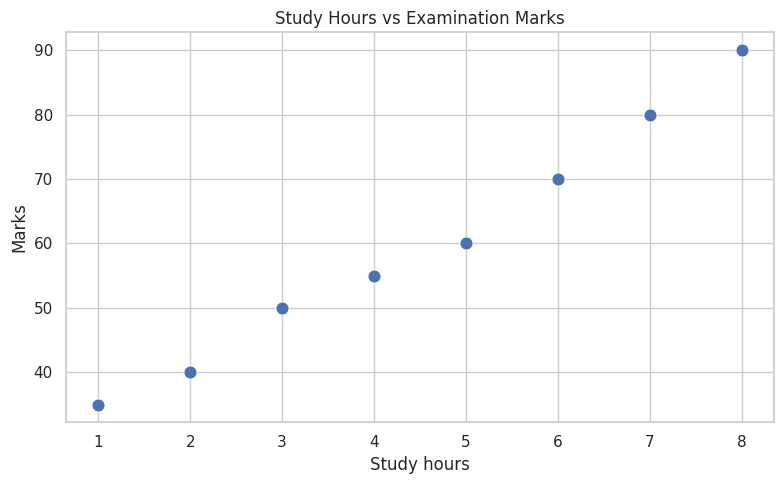

In [10]:
study_hours = [1, 2, 3, 4, 5, 6, 7, 8]
student_marks = [35, 40, 50, 55, 60, 70, 80, 90]

plt.figure(figsize=(8, 5))
sns.scatterplot(x=study_hours, y=student_marks, s=90)
plt.title("Study Hours vs Examination Marks")
plt.xlabel("Study hours")
plt.ylabel("Marks")
plt.tight_layout()
plt.show()

### Interpretation

The points move upwards: students with more study hours tend to have higher marks in this illustrative dataset. This indicates a positive association.

However, the chart does not prove that study hours caused the marks. Prior knowledge, attendance, teaching quality, motivation and study methods may also influence performance.

> **Correlation does not imply causation.**

## 13. Correlation coefficient

Pearson's correlation coefficient, usually written as \(r\), measures the strength and direction of a **linear** association between two numerical variables.

Its value ranges from −1 to +1:

| Correlation | Interpretation |
|---:|---|
| +1 | Perfect positive linear relationship |
| Close to +1 | Strong positive linear relationship |
| 0 | No linear correlation |
| Close to −1 | Strong negative linear relationship |
| −1 | Perfect negative linear relationship |

A correlation near zero does not necessarily mean the variables are unrelated; they may have a non-linear relationship.

In [11]:
r = np.corrcoef(study_hours, student_marks)[0, 1]
print("Pearson correlation:", round(r, 3))

Pearson correlation: 0.993


### Interpret the coefficient carefully

- The sign (+ or −) gives the direction.
- The magnitude (distance from zero) gives the strength of the linear association.
- Correlation does not establish cause and effect.
- Outliers can influence Pearson correlation.
- Always inspect the scatter plot as well as the coefficient.

## 14. Correlation heatmap

A heatmap displays pairwise correlation values between numerical variables. It is especially useful when a dataset has several numerical columns.

,Study_Hours,Marks,Attendance
0,1,30,40
1,2,35,45
2,3,40,50
3,4,45,55
4,5,50,60
5,6,55,65
6,7,60,70
7,8,65,80
8,9,75,85
9,10,150,90


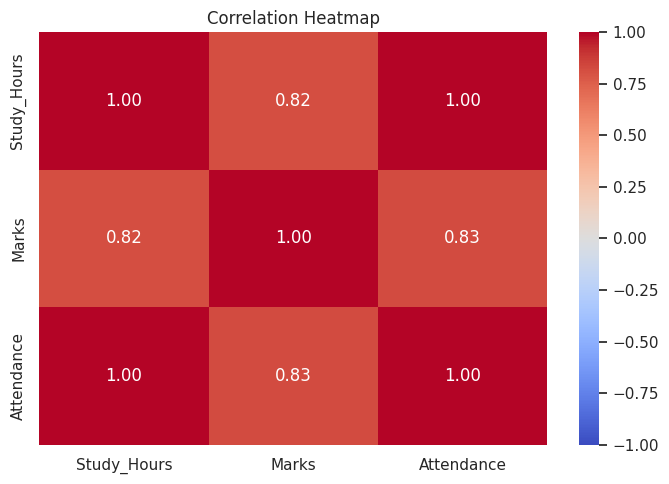

In [12]:
student_data = pd.DataFrame({
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Marks": [30, 35, 40, 45, 50, 55, 60, 65, 75, 150],
    "Attendance": [40, 45, 50, 55, 60, 65, 70, 80, 85, 90]
})

display(student_data)

correlation_matrix = student_data.corr(numeric_only=True)

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### How to read a heatmap

- Each cell contains the correlation between two variables.
- Values near +1 indicate stronger positive linear association.
- Values near −1 indicate stronger negative linear association.
- Values near 0 indicate weaker linear association.
- The diagonal is 1 because each variable is perfectly correlated with itself.

**Caution:** The unusual marks value of 150 may influence the correlation. Investigate outliers and data quality before drawing conclusions.

# Part E — Complete EDA Workflow

## 15. A practical sequence for analysing a dataset

Use this workflow when you receive a new dataset:

1. **Inspect:** Understand the rows, columns, data types and missing values.
2. **Summarise:** Calculate count, mean, median, quartiles and standard deviation.
3. **Explore distributions:** Use histograms and skewness.
4. **Screen for unusual values:** Use boxplots and IQR.
5. **Compare spread:** Examine range, standard deviation and IQR.
6. **Explore relationships:** Use scatter plots and correlation heatmaps.
7. **Communicate:** Describe what the evidence shows, its limitations and what to investigate next.

In [13]:
# Create a small integrated dataset
df = pd.DataFrame({
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Marks": [30, 35, 40, 45, 50, 55, 60, 65, 75, 150],
    "Attendance": [40, 45, 50, 55, 60, 65, 70, 80, 85, 90]
})

print("First five rows:")
display(df.head())

print("Data types and non-null counts:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDescriptive statistics:")
display(df.describe())

First five rows:


,Study_Hours,Marks,Attendance
0,1,30,40
1,2,35,45
2,3,40,50
3,4,45,55
4,5,50,60


Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Study_Hours  10 non-null     int64
 1   Marks        10 non-null     int64
 2   Attendance   10 non-null     int64
dtypes: int64(3)
memory usage: 372.0 bytes

Missing values:
Study_Hours    0
Marks          0
Attendance     0
dtype: int64

Descriptive statistics:


,Study_Hours,Marks,Attendance
count,10.00000,10.000000,10.000000
mean,5.50000,60.500000,64.000000
std,3.02765,34.355171,17.126977
min,1.00000,30.000000,40.000000
25%,3.25000,41.250000,51.250000
50%,5.50000,52.500000,62.500000
75%,7.75000,63.750000,77.500000
max,10.00000,150.000000,90.000000


## 16. Distribution, skewness and outlier screening

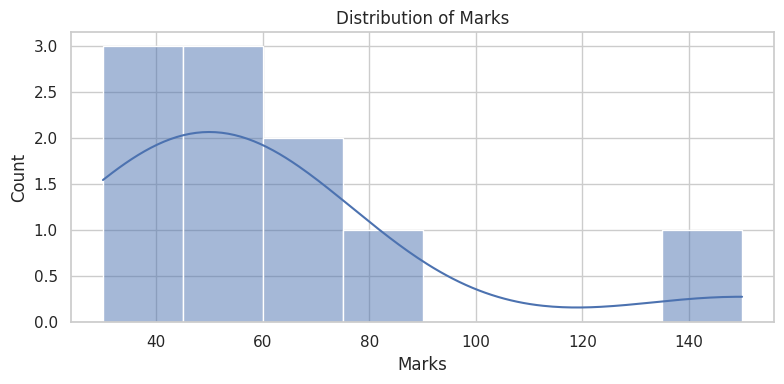

Marks skewness: 2.266


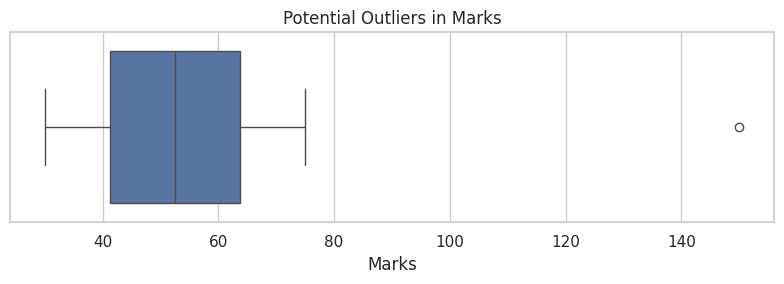

In [14]:
# Histogram
plt.figure(figsize=(8, 4))
sns.histplot(df["Marks"], kde=True, bins=8)
plt.title("Distribution of Marks")
plt.xlabel("Marks")
plt.tight_layout()
plt.show()

print("Marks skewness:", round(df["Marks"].skew(), 3))

# Boxplot
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["Marks"])
plt.title("Potential Outliers in Marks")
plt.tight_layout()
plt.show()

## 17. Relationship analysis

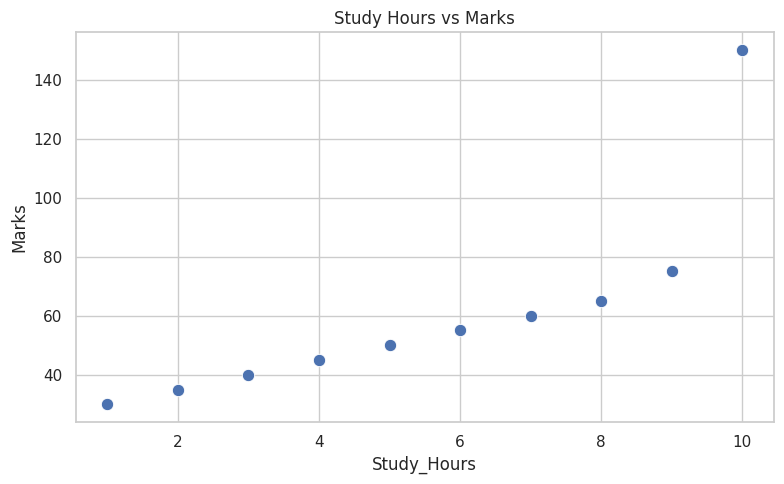

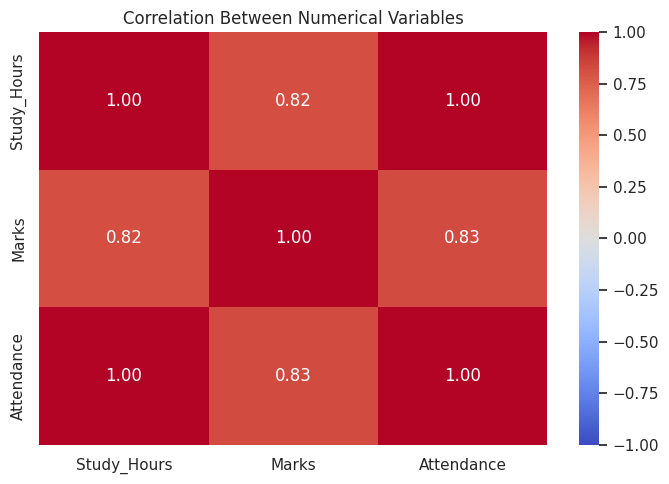

In [15]:
# Scatter plot
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Study_Hours", y="Marks", s=80)
plt.title("Study Hours vs Marks")
plt.tight_layout()
plt.show()

# Correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True,
            cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

### Interpretation questions

1. Is the marks distribution positively or negatively skewed?
2. Which observation appears unusual?
3. What should be checked before deciding whether to remove it?
4. Do study hours and marks show a positive, negative or unclear association?
5. Could the unusual value influence the correlation coefficient?
6. What additional variables would help explain student performance?

Do not make a decision from one chart alone. Combine visual evidence, numerical summaries and subject knowledge.

## 18. Sensitivity check: what happens if an unusual value is excluded?

This is an analytical demonstration only. We compare correlation with all observations and with the last observation excluded.

**Do not remove a value merely because it changes the result.** First verify whether it is an error or a valid observation. If it is valid, it may need to remain in the analysis.

In [16]:
corr_all = df["Study_Hours"].corr(df["Marks"])

# Sensitivity comparison only; not an automatic data-cleaning instruction
df_without_last = df.iloc[:-1]
corr_without_last = df_without_last["Study_Hours"].corr(df_without_last["Marks"])

print("Correlation with all observations:      ", round(corr_all, 3))
print("Correlation excluding last observation:", round(corr_without_last, 3))

Correlation with all observations:       0.82
Correlation excluding last observation: 0.995


# Part F — Classroom Activity

## 19. Become a data detective

Work individually or in pairs. Use the integrated dataset from Part E.

### Questions

1. Is the marks distribution positively or negatively skewed? Support your answer with the histogram and skewness value.
2. Does the dataset contain a potential outlier? Explain how the boxplot and IQR method identify it.
3. What does the range tell us about the marks?
4. Do study hours and marks show a positive, negative or unclear relationship?
5. Can we conclude that more study hours always cause higher marks? Explain.
6. How would your interpretation change if the value 150 were verified as a data-entry error?
7. Which additional variables could help explain student performance?

### Suggested student submission

Prepare a short report with:
- A brief description of the dataset.
- A histogram, boxplot, scatter plot and correlation heatmap.
- Two or three numerical findings.
- A written interpretation and limitations.

## 20. Quick knowledge check

Try these questions before reading the answers.

**Q1.** A histogram has a long tail towards higher values. What is the skewness?

**Q2.** Which chart is commonly used to screen for potential outliers?

**Q3.** Two groups have the same mean, but one has a much larger standard deviation. What does this mean?

**Q4.** What does a correlation coefficient of −0.85 suggest?

**Q5.** Does a strong correlation prove that one variable causes the other?

### Answers

1. Positive (right) skewness.
2. Boxplot.
3. The group with the larger standard deviation has greater variability.
4. A strong negative linear association.
5. No. Correlation does not prove causation.

# 21. How to write an interpretation of a chart

Use this four-step structure in assignments and analytical reports:

1. **Describe:** What does the chart show?
2. **Support:** Which statistic supports the observation?
3. **Interpret:** What could the pattern mean in context?
4. **Qualify:** What are the limitations or alternative explanations?

### Example interpretation

“The salary histogram is right-skewed because most salaries are concentrated at lower values, while a small number of higher salaries extend the right tail. The mean may therefore exceed the median. Reporting both mean and median provides a more complete summary.”

This approach moves beyond simply naming a chart or describing its colour.

# 22. Final summary

| Concept | What it reveals | Python functions |
|---|---|---|
| Skewness | Shape and asymmetry | `sns.histplot()`, `Series.skew()` |
| Outliers | Potentially unusual observations | `sns.boxplot()`, `quantile()` |
| Spread | Degree of variability | `describe()`, `std()`, `range`, IQR |
| Relationships | Linear association between variables | `sns.scatterplot()`, `corr()`, `sns.heatmap()` |

**Final takeaway:** Visualisation helps us see what data is communicating before we build a statistical or machine learning model. Good analysis combines charts, numerical evidence, context and careful interpretation.